# CVAE-GAN: compressing the predicted crowd frame into 10 numbers

The FoV predictor in `../../predictor/` turns the last five crowd frames into a **predicted crowd frame** $\hat F_k$: a
10×20 grid with, for every tile, the expected share of the crowd looking at it 5 s later. That is 200 numbers.

This notebook compresses each predicted frame into a latent vector $z_k$ of **10 numbers**, one per SVC layer, which
is then squashed by a sigmoid so that each of the 10 numbers lies between 0 and 1. The
model that does this is the variational auto-encoder with a discriminator
(CVAE-GAN) of [14]; its architecture, loss and training are used here. It has three networks:

| network | job | kept after training? |
|---|---|---|
| **encoder** | $\hat F_k$ (200 numbers) → a mean $\mu_{z,k}$ and a spread $\sigma_{z,k}$ for each of the 10 latent slots | **yes**: it produces $z_k$ |
| **decoder** | $\mathrm{sigmoid}(z_k)$ (10 numbers in (0, 1)) → a redrawn frame $X_\mathrm{recon}$ (200 numbers) | no: it only teaches the encoder |
| **discriminator** | a frame → probability that it is a real predicted frame rather than a redrawn one | no: it only teaches the decoder |

The idea: if the decoder can redraw the 200 tiles from the 10 numbers alone, those 10 numbers have captured what
matters about the frame.

```
 5 crowd frames       pretrained predictor        encoder              draw   squash
 F_{k-5} .. F_{k-1}  ──▶  F_hat_k (10x20)  ──▶  mu, sigma (10)  ──▶  z_k  ──▶  sigmoid(z_k) (10 numbers in (0, 1))
```

The predictor is **pretrained**: its trained weights are loaded from its `.pt` file and only used to produce $\hat F_k$; nothing here
changes them.

## What the notebook does

1. **Loads the pretrained predictor** (section 1).
2. **Builds the training frames** (section 2): every epoch draws a random group of 10 viewers, averages their FoV
   maps into crowd frames, and runs the pretrained predictor to get 7 predicted frames $\hat F_6, \dots, \hat F_{12}$.
3. **Defines the three networks** (section 3) and **the loss** (section 4).
4. **Trains** for 988 epochs, one group and one update per epoch (section 5).
5. **Evaluates** the reconstruction on a held-out group and checks how many of the 10 latent slots carry information
   (section 6).
6. **Shows the compressed latent vectors** $\mathrm{sigmoid}(z_k)$ of the test group (section 7).

This notebook trains the model once, with the equal weights $\tau_1 = \tau_2 = \tau_3 = \tfrac13$, to show how it works
and why equal weights cannot be used on these frames. The choice of the loss weights and of the input scale is made in the three
experiment notebooks in this folder (`sport_vae_normalised_tiles.ipynb`, `sport_vae_diff_weights.ipynb`, `sport_vae_normalised_and_diff_weights.ipynb`), where every setting is trained several times on several splits of the viewers
and scored on viewers that the choice never saw. The final encoder is saved by
`sport_vae_normalised_and_diff_weights.ipynb`.

## References

- **[13]** D. Saxena and J. Cao, "Multimodal Spatio-Temporal Prediction with Stochastic Adversarial Networks,"
  *ACM TIST*, vol. 13, no. 2, 2022. (Layer types, LeakyReLU, learning rate.)
- **[14]** X. Nie, C. Wang, T. Zhou, "Mobility-Aware Cooperative Caching in IoVs Based on Secure Asynchronous Federated
  and Deep Reinforcement Learning," *IEEE Internet of Things Journal*, vol. 12, no. 12, 2025.
  (The CVAE-GAN architecture and its loss.)

Both papers are behind IEEE Xplore / ACM access. Everything this notebook takes from them (the architecture, the loss
and the training settings) is written out in the sections below, so the notebook can be read on its own.

## Files

```
predictor_vae/
├── dataset/360dataset/sensory/tile/          input: <video>/<prefix>_<user>_tile.csv per viewer
├── predictor/
│   └── sport/predictor_weights_sport.pt          input: the pretrained FoV predictor
└── vae/
    └── sport/                             one folder per video (run every notebook with it as the working directory)
        ├── sport_vae.ipynb                this notebook
        ├── sport_vae_normalised_tiles.ipynb, sport_vae_diff_weights.ipynb,
        │   sport_vae_normalised_and_diff_weights.ipynb   the three experiments (run in this order)
        ├── sport_frozen_wt.pt                the final encoder (written by sport_vae_normalised_and_diff_weights.ipynb)
        ├── results/                          output: the runs of the experiments
        └── figures/                          output: PNGs of the plots below
```

Run `../../predictor/sport/fov_predictor_sport.ipynb` first if `sport/predictor_weights_sport.pt` does not exist yet. Setup is the same
as for the predictor (`pip install -r requirements.txt` in the project root).

In [1]:
import os, re, glob, time, random
from dataclasses import dataclass

import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

print("PyTorch:", torch.__version__)

# Paths are relative to this notebook's folder (run with vae/sport/ as the working directory):
#   ../../dataset/360dataset/sensory/tile/          input:  one tile CSV per viewer
#   ../../predictor/sport/predictor_weights_sport.pt input:  the pretrained FoV predictor
#   ./figures/                                   output: the figures
DATA_ROOT      = os.path.join("..", "..", "dataset", "360dataset")
PREDICTOR_FILE = os.path.join("..", "..", "predictor", "sport", "predictor_weights_sport.pt")
OUT_DIR        = "."
FIG_DIR        = "figures"

assert os.path.isdir(os.path.join(DATA_ROOT, "sensory", "tile")), \
    f"no sensory/tile under {DATA_ROOT}; run the notebook with vae/sport/ as the working directory"
assert os.path.exists(PREDICTOR_FILE), \
    f"{PREDICTOR_FILE} not found; run ../../predictor/sport/fov_predictor_sport.ipynb first"
os.makedirs(FIG_DIR, exist_ok=True)

DEVICE = torch.device("cpu")       
torch.use_deterministic_algorithms(True)

# colours used in the line charts (validated for colour-blind separation; lines also differ in style)
BLUE, ORANGE, GREEN, GREY = "#1f5fbf", "#d9480f", "#2b8a3e", "#7a7a7a"
pd.set_option("display.width", 200)

print("DATA_ROOT      =", DATA_ROOT)
print("PREDICTOR_FILE =", PREDICTOR_FILE)
print("outputs        ->", OUT_DIR)

PyTorch: 2.15.0+cpu


DATA_ROOT      = ../../dataset/360dataset
PREDICTOR_FILE = ../../predictor/sport/predictor_weights_sport.pt
outputs        -> .


## 1. The trained FoV predictor

The checkpoint holds the predictor's weights and the settings it was trained with (`cfg`: video, sampling interval,
order $n = 5$, grid $W \times H = 20 \times 10$, ...). The same settings are reused here, so the crowd frames are
built exactly as the predictor expects them.

The predictor takes the last five crowd frames, oldest first, shape `(batch, 10, 20, 5)`, and returns the predicted
frame, shape `(batch, 10, 20)`. It is put in `eval()` mode with `requires_grad = False` on every weight, and is only
ever called inside `torch.no_grad()`.

In [2]:
class CircularPad(nn.Module):
    # wrap columns (longitude, the 360-degree seam), zero-pad rows (latitude). x is (batch, C, H, W)
    def __init__(self, p):
        super().__init__(); self.p = p
    def forward(self, x):
        p = self.p
        x = torch.cat([x[..., -p:], x, x[..., :p]], dim=3)
        return nn.functional.pad(x, (0, 0, p, p))


class Order5Predictor(nn.Module):
    def __init__(self, n=5, width=16):
        super().__init__()
        self.pad1  = CircularPad(1)
        self.conv1 = nn.Conv2d(n, width, 3)
        self.pad2  = CircularPad(2)
        self.conv2 = nn.Conv2d(width, width, 3, dilation=2)
        self.head  = nn.Conv2d(width, 1, 1)

    def forward(self, x):                                       # x: (batch, H, W, n), oldest map first
        h = x.permute(0, 3, 1, 2)
        h = torch.relu(self.conv1(self.pad1(h)))
        h = torch.relu(self.conv2(self.pad2(h)))
        return torch.sigmoid(self.head(h)).squeeze(1)          # (batch, H, W), values in (0, 1)


ck = torch.load(PREDICTOR_FILE, map_location=DEVICE)
cfg = ck["cfg"]                                                 # the predictor's settings, as a dict
predictor = Order5Predictor(cfg["n"], cfg["width"]).to(DEVICE)
predictor.load_state_dict(ck["predictor"])
predictor.eval()
for p in predictor.parameters():
    p.requires_grad_(False)

BASE_RATE = ck["base_rate"]                                     # mean tile occupancy over all 50 viewers
U         = ck["U"]                                             # the 50 viewers
H, W, N   = cfg["H"], cfg["W"], cfg["n"]
N_SAMPLES = cfg["video_seconds"] // cfg["sample_every_s"]       # 12 samples per viewer, one every 5 s
KS        = list(range(N + 1, N_SAMPLES + 1))                   # the 7 predicted time steps k = 6..12
PRED_EPOCHS = -(-int(cfg["video_hours"] * 3600)
                // (cfg["users_per_epoch"] * (N_SAMPLES - N) * cfg["sample_every_s"]))   # 494


@torch.no_grad()
def predict(X):
    # X: (batch, H, W, n) numpy, oldest frame first  ->  (batch, H, W) numpy
    return predictor(torch.from_numpy(np.asarray(X, np.float32)).to(DEVICE)).cpu().numpy()


print(f"loaded predictor: video '{cfg['video']}', order n = {N}, grid {H} x {W}, "
      f"{sum(p.numel() for p in predictor.parameters()):,} weights, trainable: "
      f"{sum(p.numel() for p in predictor.parameters() if p.requires_grad)}")
print(f"base rate = {BASE_RATE:.4f},  {len(U)} viewers,  predicted time steps k = {KS[0]}..{KS[-1]}")

loaded predictor: video 'sport', order n = 5, grid 10 x 20, 3,073 weights, trainable: 0
base rate = 0.1612,  50 viewers,  predicted time steps k = 6..12


## 2. The training frames: one random group of 10 viewers per epoch

**One sample is one predicted crowd frame** $X = \hat F_k$: a 10×20 grid of values in [0, 1] for one 5-second
interval. The model never sees individual viewers.

Each epoch:

| step | what happens | notation |
|---|---|---|
| 1 | **draw a group** of 10 viewers out of the 50 | one draw from $\binom{50}{10}$ |
| 2 | **average their FoV maps** into one crowd frame per interval | $F_k = \frac{1}{10}\sum_{u} G_{u,k}$, $k = 1, \dots, 12$ |
| 3 | **run the pretrained predictor** on every window of 5 consecutive frames: $F_1..F_5 \to \hat F_6$, ..., $F_7..F_{11} \to \hat F_{12}$ | 7 predicted frames |
| 4 | **encode each frame on its own** into its own $z_k$ | 7 latent vectors $z_6, \dots, z_{12}$, 10 numbers each |
| 5 | **one batch update** from the 7 frames (section 5) | the loss is averaged over the 7 frames |

The 7 frames are 7 independent samples. While streaming, the encoder receives one predicted frame per interval and
turns it into $z_k$ with nothing carried over to $k+1$; training does the same. The frames share an epoch only so
that each update is averaged over 7 examples instead of 1.

**Why the predictor's output and not the true crowd frames?** While streaming, the encoder only ever sees the
predictor's output, so it is trained on exactly that.

**The groups.**

1. A **test group** of 10 viewers is drawn first and kept aside: no epoch may use exactly these 10 viewers
   together. Its 7 frames are scored once, after training.
2. **One new group per epoch**, for 988 epochs (twice 494, the epoch count of the predictor's first training procedure). A draw that repeats the test group or an
   earlier group is discarded and drawn again. Single viewers do come back, in different company.

| set | groups | frames | used for |
|---|---|---|---|
| training | 988, one per epoch | 988 × 7 = 6,916 | the weight updates; each frame is used in exactly one update |
| test | 1 | 7 ($k = 6..12$) | scored once after the last epoch |

The test viewers also appear in other epochs' groups. What is new is their *combination*, and therefore their crowd
frames. The test score measures how well the model summarises a new crowd frame made of familiar viewers.

All model and training settings are in `VCfg` below.

In [3]:
@dataclass
class VCfg:
    L: int = 10                     # latent size = number of SVC layers
    hidden: tuple = (128, 64)       # encoder 200 -> 128 -> 64 -> z,  decoder L -> 64 -> 128 -> 200
    d_hidden: tuple = (128, 64)     # discriminator 200 -> 128 -> 64 -> 1
    leak: float = 0.2               # LeakyReLU slope
    tau: tuple = (1 / 3, 1 / 3, 1 / 3)   # (tau_1 encoder, tau_2 decoder, tau_3 discriminator), must sum to 1
    epochs: int = 2 * PRED_EPOCHS        # 2 x 494 = 988; one group and one update per epoch
    crowd_size: int = cfg["users_per_epoch"]   # 10 viewers per group
    lr: float = 1e-3                # learning rate of [13]
    decay: float = 1e-6             # time decay of [13]: lr_t = lr / (1 + decay * t)


vcfg = VCfg()
assert abs(sum(vcfg.tau) - 1) < 1e-9, "tau_1 + tau_2 + tau_3 must be 1"


# ---- the viewers' FoV maps: 12 samples G_{u,k} per viewer, one every 5 s ----
def parse_tile_csv(path):
    # ragged 'frame, tile, tile, ...' CSV  ->  (n_frames, H, W) array of 0/1
    occ = []
    with open(path) as f:
        f.readline()
        for line in f:
            parts = [p.strip() for p in line.strip().split(",")]
            if not parts or parts[0] == "":
                continue
            g = np.zeros((H, W), np.float32)
            for x in (int(p) for p in parts[1:] if p != ""):
                j, i = divmod(x, W)                       # row j (latitude), column i (longitude)
                if 0 <= j < H and 0 <= i < W:
                    g[j, i] = 1.0
            occ.append(g)
    return np.stack(occ)


def fov_samples(occ):
    # the 12 samples G_{u,1}..G_{u,12}: the frame at 5, 10, ..., 60 s
    step = cfg["sample_every_s"] * cfg["fps"]
    return occ[[min(k * step, len(occ)) - 1 for k in range(1, N_SAMPLES + 1)]]


tile_dir = os.path.join(DATA_ROOT, "sensory", "tile")
G = {u: fov_samples(parse_tile_csv(os.path.join(tile_dir, cfg['folder'], f"{cfg['prefix']}_{u}_tile.csv"))) for u in U}


# ---- crowd frames and the pretrained predictor ----
def combined(users):
    # F_k = mean of the group's G_{u,k},  k = 1..12   ->  (12, H, W)
    return np.mean([G[u] for u in users], axis=0)


def crowd_frames(s):
    # one group (indices into U)  ->  its 7 predicted frames F_hat_6..F_hat_12, shape (7, H, W)
    F = combined([U[i] for i in s])
    X_in = np.stack([np.moveaxis(F[k - 1 - N:k - 1], 0, -1) for k in KS])     # (7, H, W, n), oldest first
    return predict(X_in).astype(np.float32)


# ---- the groups: the test group first, then one new group per epoch ----
rng_v = np.random.default_rng(1)       # fixed: every notebook uses the same groups and test group

def draw_crowd():
    return tuple(sorted(rng_v.choice(len(U), vcfg.crowd_size, replace=False).tolist()))

VTEST_SET = draw_crowd()
v_used, VEPOCH_SETS = {VTEST_SET}, []
while len(VEPOCH_SETS) < vcfg.epochs:
    s = draw_crowd()
    if s in v_used:                                   # same 10 as the test group or an earlier epoch: draw again
        continue
    v_used.add(s)
    VEPOCH_SETS.append(s)

U_vtest = [U[i] for i in VTEST_SET]
A_te_v  = crowd_frames(VTEST_SET)                     # the 7 test frames, scored once after training
A_te_vt = torch.from_numpy(A_te_v).to(DEVICE)

picks = pd.Series([U[i] for s in VEPOCH_SETS for i in s]).value_counts().reindex(U).fillna(0).astype(int)
print(vcfg)
print(f"\none epoch : 1 group of {vcfg.crowd_size} viewers -> {len(KS)} predicted frames -> {len(KS)} latent vectors -> 1 update")
print(f"epochs    : {vcfg.epochs} distinct groups, {vcfg.epochs * len(KS)} training frames in all")
print(f"viewers picked at least once: {(picks > 0).sum()} of {len(U)}; picks per viewer: min {picks.min()}, max {picks.max()}")
print(f"test group: {U_vtest}")
print(f"predicted frame values on the test group: [{A_te_v.min():.3f}, {A_te_v.max():.3f}]")

VCfg(L=10, hidden=(128, 64), d_hidden=(128, 64), leak=0.2, tau=(0.3333333333333333, 0.3333333333333333, 0.3333333333333333), epochs=988, crowd_size=10, lr=0.001, decay=1e-06)

one epoch : 1 group of 10 viewers -> 7 predicted frames -> 7 latent vectors -> 1 update
epochs    : 988 distinct groups, 6916 training frames in all
viewers picked at least once: 50 of 50; picks per viewer: min 169, max 221
test group: ['user02', 'user07', 'user13', 'user16', 'user20', 'user22', 'user33', 'user39', 'user42', 'user46']
predicted frame values on the test group: [0.005, 0.960]


### 2.1 What the training frames look like

The test group's 7 time steps. Top row: the actual crowd frame $F_k$ (the share of the 10 viewers looking at each
tile). Bottom row: the pretrained predictor's frame $\hat F_k$, made from the five frames before it. The bottom row is
what the encoder receives. The frames all have one bright region where most of the group looks, and they differ
from each other only in where that region sits and how spread out it is. That is the information the 10 numbers
have to capture.

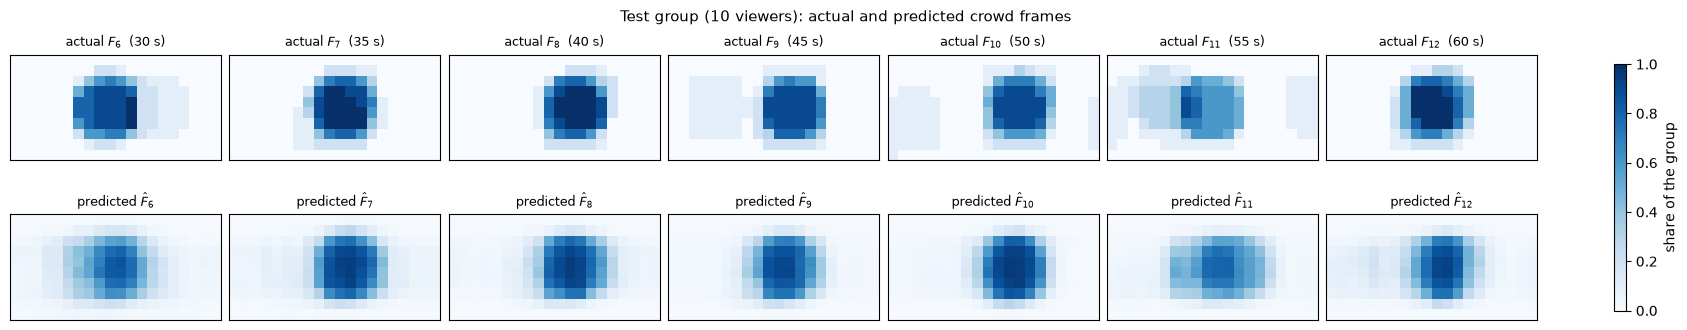

In [4]:
F_test = combined(U_vtest)
vmax = float(max(F_test.max(), A_te_v.max()))
fig, axes = plt.subplots(2, len(KS), figsize=(2.4 * len(KS), 3.4), constrained_layout=True)
for col, k in enumerate(KS):
    axes[0, col].imshow(F_test[k - 1], cmap="Blues", vmin=0, vmax=vmax, interpolation="nearest")
    axes[0, col].set_title(f"actual $F_{{{k}}}$  ({5 * k} s)", fontsize=9)
    im = axes[1, col].imshow(A_te_v[col], cmap="Blues", vmin=0, vmax=vmax, interpolation="nearest")
    axes[1, col].set_title(f"predicted $\\hat F_{{{k}}}$", fontsize=9)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="share of the group")
fig.suptitle(f"Test group ({len(U_vtest)} viewers): actual and predicted crowd frames", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, "test_group_frames.png"), dpi=150)
plt.show()

## 3. The three networks

The model follows the CVAE-GAN architecture of [14]: an encoder, a decoder that also acts as the
generator of a GAN, and a discriminator. The diagram below shows our implementation of it. [14] specifies the
networks and how they connect; the layer sizes are ours and the layer types follow [13], a VAE-GAN for grid-shaped data:
fully connected hidden layers with **LeakyReLU**, and a **sigmoid** on the discriminator's output.

![CVAE-GAN architecture](figures/cvaegan_architecture.png)

The predicted frame $X = \hat F_k$ is encoded into a mean and a log-variance for each of the 10 slots, one value per
slot is drawn to give $z_k$, $z_k$ is squashed into (0, 1) by a sigmoid, and the decoder redraws the frame from
$\mathrm{sigmoid}(z_k)$ alone. The discriminator sees both the real
frame and the redrawn one and says which is which. Each network has its own line of the loss (orange, section 4).
After training, only the blue part is kept: the encoder, the draw and the sigmoid, which produce $\mathrm{sigmoid}(z_k)$.

| network | input | layers | output | weights |
|---|---|---|---|---|
| **encoder** | $X$, 200 | 200 → 128 → 64 (LeakyReLU); two linear heads 64 → 10 | $\mu_{z,k}$ (10), $\log\sigma^2_{z,k}$ (10) | 35,284 |
| **decoder** (= generator) | $\mathrm{sigmoid}(z_k)$, 10 | 10 → 64 → 128 (LeakyReLU); linear 128 → 200; sigmoid | $X_\mathrm{recon}$, 200 tiles in (0, 1) | 34,824 |
| **discriminator** | a frame, 200 | 200 → 128 → 64 (LeakyReLU); linear 64 → 1; sigmoid | $D \in (0, 1)$ | 34,049 |

**The pieces:**

- **Flatten.** The 10×20 grid is read row by row into a list of 200 numbers, because these layers take a flat list.
- **LeakyReLU** ($x$ if $x \ge 0$, else $0.2x$). A unit that outputs 0 passes no gradient back; the leaky version always
  passes a little, which keeps both players of the GAN learning.
- **Two heads.** From the same 64 numbers, one head gives the 10 means $\mu_{z,k}$ and the other the 10 values
  $\log\sigma^2_{z,k}$. The log is used because a network can output any real number, while a variance must be
  positive: $\sigma_{z,k} = \exp(\tfrac12\log\sigma^2_{z,k})$ always is.
- **Drawing the latent vector.** For each slot $j = 1, \dots, 10$, a standard normal number is drawn and then shifted by the mean
  and scaled by the spread the encoder gave for that slot:

  $$z_k[j] = \mu_{z,k}[j] + \sigma_{z,k}[j]\,\varepsilon_j, \qquad \varepsilon_j \sim \mathcal N(0, 1), \qquad
  \sigma_{z,k}[j] = \exp\big(\tfrac12 \log\sigma^2_{z,k}[j]\big)$$

  so $z_k[j] \sim \mathcal N(\mu_{z,k}[j], \sigma^2_{z,k}[j])$. Example: $\mu = 0.4$, $\sigma = 0.5$ and a draw
  $\varepsilon = -1.2$ give $z = 0.4 + 0.5 \times (-1.2) = -0.2$. Writing the draw this way (the *reparameterisation
  trick*) puts all the randomness in $\varepsilon$, which does not depend on the weights, so the gradient of the
  reconstruction error can flow back through $\mu_{z,k}$ and $\sigma_{z,k}$ to the encoder. `draw_z` in the code below
  is exactly this formula. The same drawn $z_k$ is decoded once, and that frame is both $X_\mathrm{recon}$ and the frame
  the discriminator judges.
- **Squashing the latent vector into (0, 1).** Before the decoder, every number of the drawn latent vector passes through a sigmoid,
  $\mathrm{sigmoid}(z_k) = 1/(1 + e^{-z_k})$, so the 10 numbers that stand for the frame all lie between 0 and 1. The
  decoder only ever sees these squashed values, so the reconstruction error measures what survives the squashing.
  Line 1 of the loss is computed on $z_k$ (its mean and spread) before the sigmoid.
- **Decoder output.** A sigmoid keeps every tile in (0, 1), like the predictor's. The last layer's bias starts at the
  log-odds of the base rate, so the untrained decoder draws the average brightness (the base rate printed in section 1) instead of
  0.5 everywhere.
- **No conditioning input.** In [14] the decoder also receives per-user features (age, gender, ...), which is what
  makes the model *conditional*. Our frames come with no such features, so the decoder's input is $\mathrm{sigmoid}(z_k)$ alone.

In [5]:
def mlp(sizes, v=vcfg):
    # Linear -> LeakyReLU for every consecutive pair of widths
    return [m for a, b in zip(sizes, sizes[1:]) for m in (nn.Linear(a, b), nn.LeakyReLU(v.leak))]


class Encoder(nn.Module):
    # X = F_hat_k  ->  (mu_{z,k}, log sigma_{z,k}^2)
    def __init__(self, v=vcfg):
        super().__init__()
        sizes = [H * W, *v.hidden]                              # 200 -> 128 -> 64
        self.body  = nn.Sequential(*mlp(sizes, v))
        self.to_mu = nn.Linear(sizes[-1], v.L)                 # mu_{z,k}
        self.to_lv = nn.Linear(sizes[-1], v.L)                 # log sigma_{z,k}^2

    def forward(self, F_hat):
        h = self.body(F_hat.flatten(1))
        return self.to_mu(h), self.to_lv(h)


class Decoder(nn.Module):
    # sigmoid(z_k)  ->  X_recon, 200 tiles in (0, 1). Also the GAN's generator.
    def __init__(self, v=vcfg):
        super().__init__()
        sizes = [v.L, *v.hidden[::-1]]                          # 10 -> 64 -> 128
        self.net = nn.Sequential(*mlp(sizes, v), nn.Linear(sizes[-1], H * W))     # 128 -> 200
        # start at the average brightness: sigmoid(bias) = base rate
        nn.init.constant_(self.net[-1].bias, float(np.log(BASE_RATE / (1 - BASE_RATE))))

    def forward(self, z):
        return torch.sigmoid(self.net(torch.sigmoid(z))).view(-1, H, W)   # z_k is squashed into (0, 1) before decoding


class Discriminator(nn.Module):
    # D(X) in (0, 1): probability that a frame is a real predicted frame
    def __init__(self, v=vcfg):
        super().__init__()
        sizes = [H * W, *v.d_hidden]                            # 200 -> 128 -> 64
        self.net = nn.Sequential(*mlp(sizes, v), nn.Linear(sizes[-1], 1))         # 64 -> 1

    def logit(self, X):
        return self.net(X.flatten(1)).squeeze(1)

    def forward(self, X):
        return torch.sigmoid(self.logit(X))


def draw_z(mu, lv):
    # z_k = mu_{z,k} + sigma_{z,k} * eps,  eps ~ N(0, 1): one draw per latent slot, differentiable in mu and sigma
    eps = torch.empty_like(mu).normal_()
    return mu + torch.exp(0.5 * lv) * eps


n_par = lambda m: sum(p.numel() for p in m.parameters())
print(f"encoder {n_par(Encoder()):,}   decoder {n_par(Decoder()):,}   discriminator {n_par(Discriminator()):,}")

encoder 35,284   decoder 34,824   discriminator 34,049


## 4. The loss

The loss is taken exactly as it is from [14]:

$$\mathcal L(X) \;=\; \tau_1\Big(-\frac12\sum_{j=1}^{10}\big(1 + \log\sigma^2_{z,j} - \mu^2_{z,j} - \sigma^2_{z,j}\big)\Big)
\;+\; \tau_2\Big(\frac12\big\lVert X - X_\mathrm{recon}\big\rVert_2^2\Big)
\;+\; \tau_3\Big(\mathbb E\big[\log D(X)\big] + \mathbb E\big[\log\big(1 - D(X_\mathrm{recon})\big)\big]\Big)$$

with $\tau_1 + \tau_2 + \tau_3 = 1$. Each line is averaged over the 7 frames of the batch. The three lines are one
function each in the code (`loss_enc`, `loss_dec`, `loss_disc`).

**Line 1, encoder: the KL charge.** The KL divergence between each slot's distribution $\mathcal N(\mu, \sigma^2)$ and
the standard normal $\mathcal N(0, 1)$, summed over the 10 slots. It is 0 when $\mu = 0$ and $\sigma = 1$ and grows as a
slot moves away from that. For one slot:

| $\mu$ | $\sigma^2$ | charge |
|---|---|---|
| 0 | 1 | 0 |
| 1 | 1 | 0.50 |
| 0 | 0.25 | 0.32 |
| 1 | 0.25 | 0.82 |

So a slot pays for every bit of information it holds: being centred away from 0, or being confident (small
$\sigma$). This keeps $z_k$ small and well scaled.

**Line 2, decoder: the reconstruction error.** Half the squared difference between input and redrawn frame, summed
over the 200 tiles. Since RMSE is the square root of the mean over 200 tiles, line 2 $= 100 \times \text{RMSE}^2$.

**Line 3, discriminator: real or redrawn?** The log-likelihood of a real-or-redrawn classifier. It is never above 0:

| the discriminator says | $D(X)$ | $D(X_\mathrm{recon})$ | line 3 |
|---|---|---|---|
| almost perfect | 0.99 | 0.01 | −0.02 |
| good | 0.90 | 0.10 | −0.21 |
| cannot tell | 0.50 | 0.50 | −1.39 |

The same formula is used in two opposite directions: the discriminator **maximises** line 3 (it wants to tell real from
redrawn), while the encoder and decoder **minimise** $\mathcal L$, which pushes the decoder to produce frames the
discriminator calls real.

**The weights.** The loss requires only $\tau_1 + \tau_2 + \tau_3 = 1$, so the values have to be chosen for the
data. This notebook starts from equal weights, $\tau_1 = \tau_2 = \tau_3 = \tfrac13$. The lines are on very different scales (line 1 can reach tens
of nats, line 2 is a few tenths), so equal weights do not mean equal influence; section 6 shows what this does.

In [6]:
def loss_enc(mu, lv):
    # line 1: -1/2 sum_j (1 + log sigma_j^2 - mu_j^2 - sigma_j^2), mean over the batch
    return torch.mean(-0.5 * torch.sum(1 + lv - mu.pow(2) - lv.exp(), dim=1))

def loss_dec(X, X_recon):
    # line 2: 1/2 ||X - X_recon||^2 summed over the 200 tiles, mean over the batch
    return torch.mean(0.5 * torch.sum(torch.square(X - X_recon), dim=(1, 2)))

def loss_disc(disc, X, X_recon):
    # line 3: E[log D(X)] + E[log(1 - D(X_recon))], via logsigmoid so log(0) never occurs
    return (torch.mean(nn.functional.logsigmoid(disc.logit(X)))
            + torch.mean(nn.functional.logsigmoid(-disc.logit(X_recon))))

def cvaegan_loss(tau, mu, lv, X, X_recon, disc):
    # L = tau_1 * line 1 + tau_2 * line 2 + tau_3 * line 3
    L_enc, L_dec, L_disc = loss_enc(mu, lv), loss_dec(X, X_recon), loss_disc(disc, X, X_recon)
    return tau[0] * L_enc + tau[1] * L_dec + tau[2] * L_disc, (L_enc, L_dec, L_disc)


def rmse(p, y):
    return float(np.sqrt(np.mean((np.asarray(p) - np.asarray(y)) ** 2)))


@torch.no_grad()
def cvae_eval(enc, dec, A_t, draws=20):
    # reconstruction RMSE decoding mu_{z,k}, and decoding drawn z_k (mean over draws)
    enc.eval(); dec.eval()
    mu, lv = enc(A_t)
    out = {"rmse": float(torch.sqrt(torch.mean(torch.square(dec(mu) - A_t))))}
    if draws:
        err = [torch.mean(torch.square(dec(draw_z(mu, lv)) - A_t)) for _ in range(draws)]
        out["rmse_sampled"] = float(torch.sqrt(torch.stack(err).mean()))
    return out

## 5. Training

The encoder and decoder want a lower $\mathcal L$; the discriminator wants a higher line 3. So the two sides take
turns, as in [13].

**One epoch** ($e = 1, \dots, 988$):

0. **Batch.** Take epoch $e$'s group, build its crowd frames and run the pretrained predictor: $X$ = the 7 frames
   $\hat F_6, \dots, \hat F_{12}$, shape (7, 10, 20).
1. **Record** the RMSE of $X$ against the decoded means $\mu_{z,k}$, with the weights before this epoch's update.
2. **Discriminator move.** Encode $X$, draw $z_k$, decode (no gradients needed), compute line 3 on the real and
   redrawn frames, and update **only the discriminator** to make line 3 larger.
3. **Encoder + decoder move.** Encode $X$, draw $z_k$ with `rsample()`, decode into $X_\mathrm{recon}$, compute
   $\mathcal L$ with the current discriminator, and update **only the encoder and decoder** to make $\mathcal L$
   smaller.

The discriminator moves first so that the decoder is judged by a discriminator that has just seen its latest frames.

| quantity | shape |
|---|---|
| $X = [\hat F_6, \dots, \hat F_{12}]$ | (7, 10, 20) |
| $\mu_{z,k}$, $\log\sigma^2_{z,k}$, $z_k$ | (7, 10) each |
| $X_\mathrm{recon}$ | (7, 10, 20) |
| $D(X)$, $D(X_\mathrm{recon})$ | (7,) each |
| line 1, line 2, line 3, $\mathcal L$ | scalars (means over the 7 frames) |

**Settings:**

| setting | value | why |
|---|---|---|
| $\tau_1, \tau_2, \tau_3$ | 1/3 each | the loss fixes only the sum; equal weights are the neutral starting point |
| epochs | 988, one group of 10 and one update per epoch | twice 494, the epoch count of the predictor's first training procedure, because one update per group gives few updates |
| optimiser | Adam, one for encoder + decoder, one for the discriminator | adapts each weight's step size; the losses have very different scales and the two players keep changing each other's landscape |
| learning rate | $\eta_t = 0.001 / (1 + 10^{-6}\,t)$, $t$ = updates so far | [13]; with 988 updates it stays at practically 0.001 |
| LeakyReLU slope | 0.2 | the common default |


In [7]:
def train_cvaegan(tau, v=vcfg, print_every=100):
    enc, dec, disc = Encoder(v).to(DEVICE), Decoder(v).to(DEVICE), Discriminator(v).to(DEVICE)
    opt_ed = torch.optim.Adam([*enc.parameters(), *dec.parameters()], lr=v.lr)
    opt_d  = torch.optim.Adam(disc.parameters(), lr=v.lr)
    scheds = [torch.optim.lr_scheduler.LambdaLR(o, lambda t: 1.0 / (1.0 + v.decay * t)) for o in (opt_ed, opt_d)]
    rows, seen = [], []
    for e in range(1, v.epochs + 1):
        X_np = crowd_frames(VEPOCH_SETS[e - 1])               # this epoch's 7 predicted frames
        X = torch.from_numpy(X_np).to(DEVICE)
        seen.append(X_np)
        rmse_before = cvae_eval(enc, dec, X, draws=0)["rmse"]
        enc.train(); dec.train(); disc.train()

        # (1) discriminator: maximise line 3, i.e. minimise -tau_3 * line 3
        with torch.no_grad():
            mu, lv = enc(X)
            X_fake = dec(draw_z(mu, lv))
        L_D = -tau[2] * loss_disc(disc, X, X_fake)
        opt_d.zero_grad(); L_D.backward(); opt_d.step()

        # (2) encoder + decoder: minimise L
        mu, lv = enc(X)
        X_recon = dec(draw_z(mu, lv))
        L, (L_enc, L_dec, L_disc) = cvaegan_loss(tau, mu, lv, X, X_recon, disc)
        opt_ed.zero_grad(); L.backward(); opt_ed.step()
        for sch in scheds:
            sch.step()

        with torch.no_grad():
            d_real, d_fake = disc(X).mean().item(), disc(X_recon).mean().item()
            rmse_drawn = float(torch.sqrt(torch.mean(torch.square(X_recon - X))))
        rows.append({"epoch": e, "L": L.item(), "L_enc": L_enc.item(), "L_dec": L_dec.item(), "L_disc": L_disc.item(),
                     "D(X)": d_real, "D(X_recon)": d_fake, "train_rmse": rmse_before, "train_rmse_drawn": rmse_drawn})
        if e == 1 or e % print_every == 0 or e == v.epochs:
            print(f"epoch {e:3d}  L {L.item():8.4f}  line1 {L_enc.item():7.4f}  line2 {L_dec.item():7.4f}  "
                  f"line3 {L_disc.item():7.4f}  D(X) {d_real:.3f}  D(X_recon) {d_fake:.3f}  batch RMSE {rmse_before:.4f}")
    return (enc, dec, disc), pd.DataFrame(rows), np.concatenate(seen)


t0 = time.time()
(enc, dec, disc), VLOG, A_tr_v = train_cvaegan(vcfg.tau)
A_tr_vt = torch.from_numpy(A_tr_v).to(DEVICE)          # all 988 x 7 training frames, for the reference points below
VLOG["train_rmse_ma"] = VLOG.train_rmse.rolling(25, min_periods=1).mean()
print(f"\n{vcfg.epochs} epochs, {len(A_tr_v)} frames, one update per epoch")

epoch   1  L   1.8219  line1  0.0562  line2  6.7864  line3 -1.3770  D(X) 0.508  D(X_recon) 0.503  batch RMSE 0.2605


epoch 100  L  -0.2159  line1  0.0051  line2  0.7217  line3 -1.3744  D(X) 0.497  D(X_recon) 0.490  batch RMSE 0.0840


epoch 200  L  -0.2430  line1  0.0084  line2  0.6166  line3 -1.3538  D(X) 0.516  D(X_recon) 0.499  batch RMSE 0.0785


epoch 300  L  -0.1913  line1  0.0078  line2  0.7851  line3 -1.3670  D(X) 0.496  D(X_recon) 0.485  batch RMSE 0.0872


epoch 400  L  -0.1841  line1  0.0057  line2  0.8079  line3 -1.3659  D(X) 0.461  D(X_recon) 0.432  batch RMSE 0.0812


epoch 500  L  -0.1594  line1  0.0023  line2  0.9994  line3 -1.4799  D(X) 0.442  D(X_recon) 0.457  batch RMSE 0.0979


epoch 600  L  -0.2267  line1  0.0018  line2  0.6011  line3 -1.2831  D(X) 0.531  D(X_recon) 0.470  batch RMSE 0.0785


epoch 700  L  -0.1904  line1  0.0024  line2  0.5475  line3 -1.1210  D(X) 0.606  D(X_recon) 0.438  batch RMSE 0.0747


epoch 800  L  -0.0856  line1  0.0009  line2  1.0917  line3 -1.3493  D(X) 0.502  D(X_recon) 0.321  batch RMSE 0.1046


epoch 900  L  -0.0844  line1  0.0036  line2  0.8872  line3 -1.1440  D(X) 0.605  D(X_recon) 0.434  batch RMSE 0.0950


epoch 988  L  -0.1919  line1  0.0008  line2  0.5421  line3 -1.1185  D(X) 0.590  D(X_recon) 0.428  batch RMSE 0.0763

988 epochs, 6916 frames, one update per epoch


## 6. Results

### 6.1 Reconstruction error

The RMSE of the redrawn frame against the encoder's own input (lower is better). It measures only what the
10-number summary throws away, not whether $\hat F_k$ was right in the first place (that is the predictor's error).

To judge the numbers, one reference that needs no VAE:

| row | what it is |
|---|---|
| **mean frame** | always redraw the average training frame; uses no information about the input, so a useful latent must beat it |
| **CVAE-GAN, decode** $\mu_z$ | the decoder given the encoder's mean (a steady measurement) |
| **CVAE-GAN, decode drawn** $z_k$ | the decoder given a random draw, averaged over 20 draws (what streaming does) |

Columns: **training frames** (all 6,916, with the final weights) and **test group** (its 7 frames, scored once now).

### 6.2 How many of the 10 slots are used?

A slot whose $\sigma_{z,k}$ stays at about 1 and $\mu_{z,k}$ at about 0 for every frame says nothing about the frame:
it has **collapsed** to the standard normal, and a value drawn from it is pure noise. The cell counts a slot as
**active** if its mean $\sigma_{z,k}$ on the test group is below 0.5.

In [8]:
mean_frame = A_tr_v.mean(0)

SPLITS = {"training frames": (A_tr_v, A_tr_vt), "test group": (A_te_v, A_te_vt)}
EV = {s: cvae_eval(enc, dec, At) for s, (_, At) in SPLITS.items()}
VSUM = pd.DataFrame({s: {
        "mean frame":                   rmse(np.broadcast_to(mean_frame, A.shape), A),
        "CVAE-GAN, decode mu_z":        EV[s]["rmse"],
        "CVAE-GAN, decode drawn z_k":   EV[s]["rmse_sampled"]}
    for s, (A, _) in SPLITS.items()})
print("Reconstruction RMSE of X = F_hat_k")
print(VSUM.round(4).to_string())

# encode the test group once: mu, sigma, one drawn z_k, its reconstruction and the discriminator's answers
with torch.no_grad():
    enc.eval(); dec.eval(); disc.eval()
    MU_te, LV_te = enc(A_te_vt)
    Z_te_t = draw_z(MU_te, LV_te)
    REC_te = dec(Z_te_t).cpu().numpy()
    D_te = disc(A_te_vt).cpu().numpy(), disc(dec(Z_te_t)).cpu().numpy()
SIG_te = np.exp(0.5 * LV_te.cpu().numpy())

print(f"\nline 1 (KL) at the last epoch: {VLOG.L_enc.iloc[-1]:.4f} nats")
print(f"mean sigma_z per slot on the test group: {SIG_te.mean(0).round(3)}")
active = SIG_te.mean(0) < 0.5
print(f"active slots: {int(active.sum())} of {vcfg.L}")

Reconstruction RMSE of X = F_hat_k
                            training frames  test group
mean frame                           0.0823      0.0715
CVAE-GAN, decode mu_z                0.0843      0.0751
CVAE-GAN, decode drawn z_k           0.0843      0.0740

line 1 (KL) at the last epoch: 0.0008 nats
mean sigma_z per slot on the test group: [0.999 0.997 0.998 1.001 0.997 1.002 0.999 0.999 1.002 1.001]
active slots: 0 of 10


### 6.3 Training curves

**Left:** the RMSE on each epoch's own 7 frames, decoding $\mu_{z,k}$ with the weights before the update. It is
jagged because every epoch brings a different group; the dark line is its 25-epoch moving average. The grey line is
the mean-frame reference on the training frames; the orange line is the test group, scored once after
training.

**Right:** the three lines of the loss over the epochs, and the discriminator's mean answers on real and redrawn
frames. When both answers sit at 0.5, the discriminator can no longer tell redrawn frames from real ones.

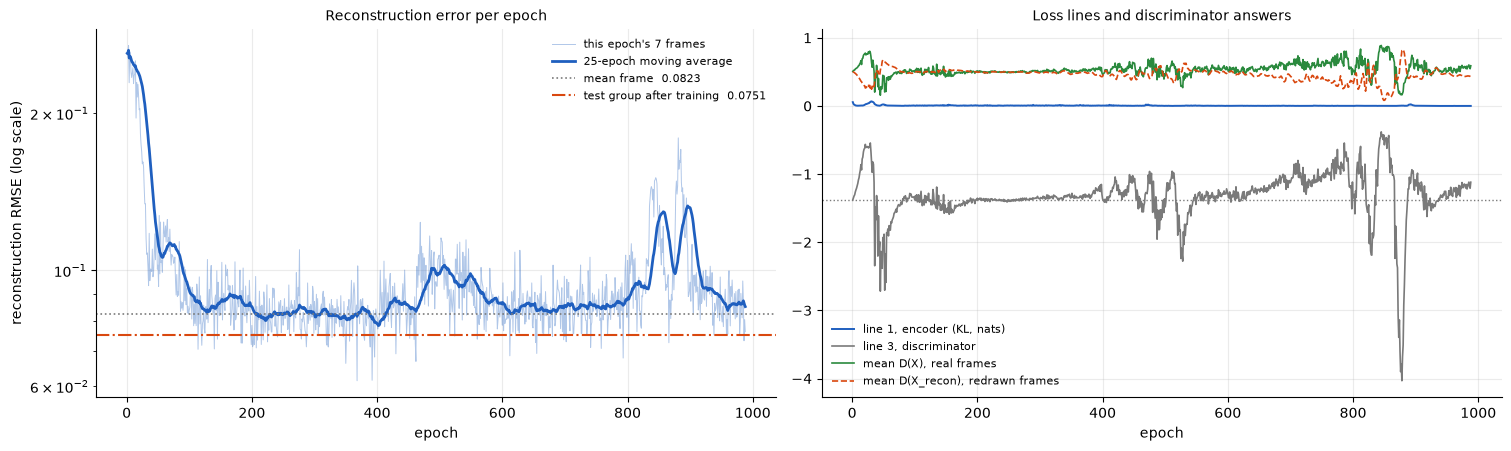

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4), constrained_layout=True)
ax = axes[0]
ax.plot(VLOG.epoch, VLOG.train_rmse, color=BLUE, lw=0.7, alpha=0.35, label="this epoch's 7 frames")
ax.plot(VLOG.epoch, VLOG.train_rmse_ma, color=BLUE, lw=2, label="25-epoch moving average")
ax.axhline(VSUM.loc["mean frame", "training frames"], color=GREY, ls=":", lw=1.2,
           label=f"mean frame  {VSUM.loc['mean frame', 'training frames']:.4f}")
ax.axhline(EV["test group"]["rmse"], color=ORANGE, ls="-.", lw=1.5,
           label=f"test group after training  {EV['test group']['rmse']:.4f}")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("reconstruction RMSE (log scale)")
ax.set_title("Reconstruction error per epoch", fontsize=10)
ax.legend(fontsize=8, frameon=False)

ax = axes[1]
ax.plot(VLOG.epoch, VLOG.L_enc, color=BLUE, lw=1.4, label="line 1, encoder (KL, nats)")
ax.plot(VLOG.epoch, VLOG.L_disc, color=GREY, lw=1.2, label="line 3, discriminator")
ax.plot(VLOG.epoch, VLOG["D(X)"], color=GREEN, lw=1.2, ls="-", label="mean D(X), real frames")
ax.plot(VLOG.epoch, VLOG["D(X_recon)"], color=ORANGE, lw=1.2, ls="--", label="mean D(X_recon), redrawn frames")
ax.axhline(-2 * np.log(2), color=GREY, ls=":", lw=1)
ax.set_xlabel("epoch"); ax.set_title("Loss lines and discriminator answers", fontsize=10)
ax.legend(fontsize=8, frameon=False)
for a in axes:
    a.grid(alpha=0.25); a.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "training_curves.png"), dpi=150)
plt.show()

### 6.4 The test group through the CVAE-GAN

Top row: the predicted frames $\hat F_k$ the encoder receives. Middle row: the decoder's redrawing from one drawn
$z_k$ (200 tiles → 10 numbers → 200 tiles). Bottom row: the absolute error per tile. The redrawn frame should have its
bright region in the same place as the input.

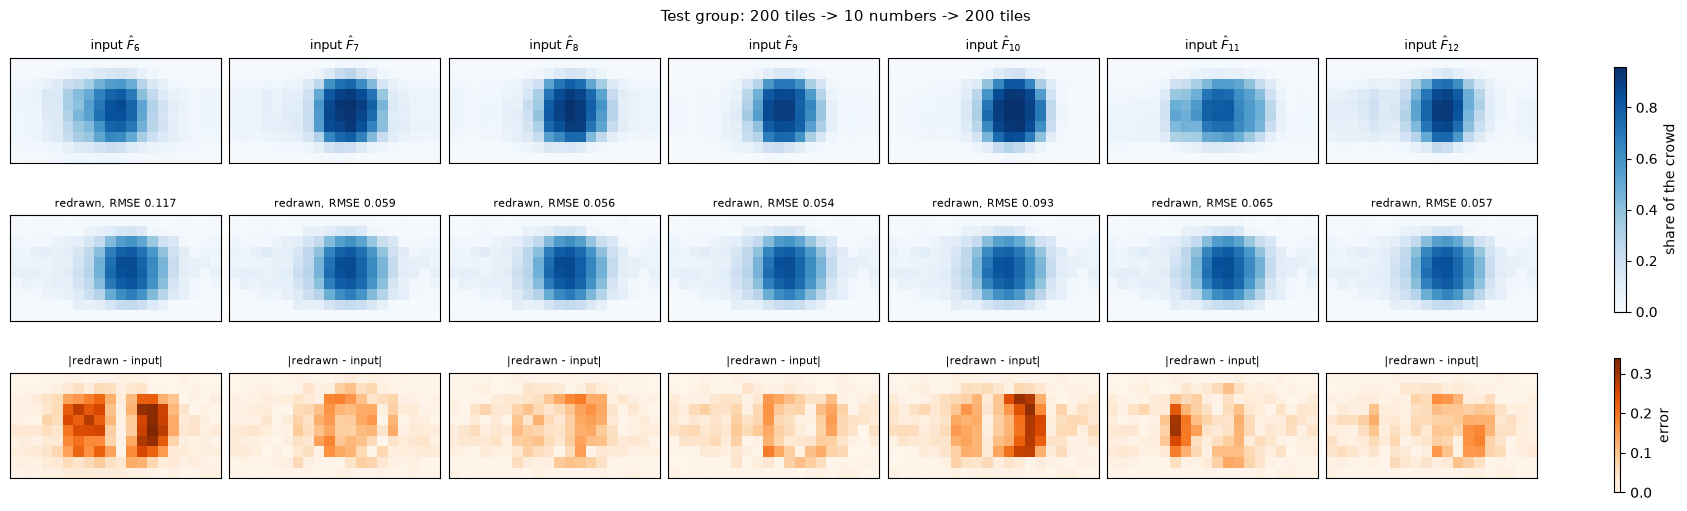

In [10]:
vm = float(max(A_te_v.max(), REC_te.max()))
err = np.abs(REC_te - A_te_v)
fig, axes = plt.subplots(3, len(KS), figsize=(2.4 * len(KS), 5.0), constrained_layout=True)
for col, k in enumerate(KS):
    im0 = axes[0, col].imshow(A_te_v[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
    axes[0, col].set_title(f"input $\\hat F_{{{k}}}$", fontsize=9)
    axes[1, col].imshow(REC_te[col], cmap="Blues", vmin=0, vmax=vm, interpolation="nearest")
    axes[1, col].set_title(f"redrawn, RMSE {rmse(REC_te[col], A_te_v[col]):.3f}", fontsize=8)
    im2 = axes[2, col].imshow(err[col], cmap="Oranges", vmin=0, vmax=float(err.max()), interpolation="nearest")
    axes[2, col].set_title("|redrawn - input|", fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im0, ax=axes[:2], shrink=0.8, label="share of the crowd")
fig.colorbar(im2, ax=axes[2], shrink=0.9, label="error")
fig.suptitle(f"Test group: 200 tiles -> {vcfg.L} numbers -> 200 tiles", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, "test_group_reconstruction.png"), dpi=150)
plt.show()

### 6.5 What each latent slot does

**Left:** each slot is swept from −2 to +2 while the others are held at their median, and the bar shows how much the
decoded frame changes (mean absolute change per tile). A slot that changes nothing is unused. **Right:** each slot's
mean $\sigma_{z,k}$ on the test group; the dotted line is the standard normal's $\sigma = 1$, which a collapsed slot
sits on. Active slots are blue, collapsed slots grey.

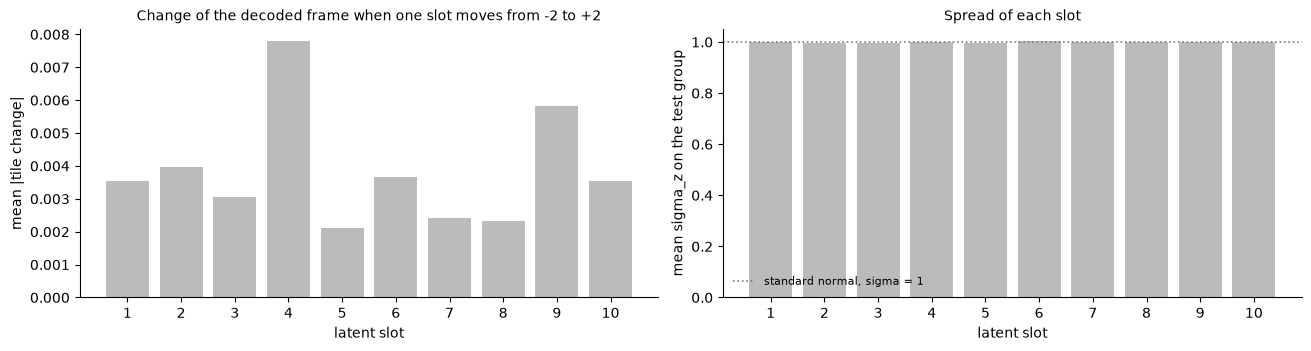

In [11]:
with torch.no_grad():
    enc.eval(); dec.eval()
    med = np.median(enc(A_tr_vt)[0].cpu().numpy(), 0)
SWING = []
for d in range(vcfg.L):
    zs = np.tile(med, (7, 1)).astype(np.float32)
    zs[:, d] = np.linspace(-2, 2, 7)
    with torch.no_grad():
        frames = dec(torch.from_numpy(zs).to(DEVICE)).cpu().numpy()
    SWING.append(float(np.abs(frames[-1] - frames[0]).mean()))

dims = np.arange(1, vcfg.L + 1)
colors = [BLUE if a else "#bbbbbb" for a in active]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.4), constrained_layout=True)
ax1.bar(dims, SWING, color=colors)
ax1.set_xlabel("latent slot"); ax1.set_ylabel("mean |tile change|")
ax1.set_title("Change of the decoded frame when one slot moves from -2 to +2", fontsize=10)
ax2.bar(dims, SIG_te.mean(0), color=colors)
ax2.axhline(1.0, color=GREY, ls=":", lw=1.2, label="standard normal, sigma = 1")
ax2.set_xlabel("latent slot"); ax2.set_ylabel("mean sigma_z on the test group")
ax2.set_title("Spread of each slot", fontsize=10); ax2.legend(fontsize=8, frameon=False)
for a in (ax1, ax2):
    a.set_xticks(dims); a.spines[["top", "right"]].set_visible(False)
fig.savefig(os.path.join(FIG_DIR, "latent_slots.png"), dpi=150)
plt.show()

### 6.6 What the results show

The cell below reads the numbers of this one training run off the results above: whether the training converged,
whether the discriminator can still tell redrawn frames from real ones, how many of the 10 slots carry information,
and whether the CVAE-GAN beats always answering the mean frame.

**Why equal weights can make the encoder carry nothing.** Line 1 charges for information; line 2 rewards it only by the
reconstruction error it removes.

- *What line 2 can gain.* Line 2 $= 100 \times \text{RMSE}^2$, so even a perfect reconstruction can lower it by only
  $100 \times (\text{mean-frame RMSE})^2$ (printed below).
- *What line 1 costs.* Moving a single slot's mean to 1 already costs 0.5 nats (table in section 4), and an encoder
  that distinguishes frames needs several slots that are both shifted and confident.

When the cost of holding information is larger than the entire possible gain, every slot stays at the standard normal
($\sigma_{z,k} \approx 1$), line 1 drops to almost 0 and the decoder draws the average frame. $z_k$ (and so
$\mathrm{sigmoid}(z_k)$) is then 10 random numbers with no information about where the crowd looks (section 7 shows
this directly).

**Experiments that fix the collapse.** Three notebooks in this folder test the two fixes (a much smaller $\tau_1$
relative to $\tau_2$, and normalised frames), with the same data, networks and training. Every setting is trained 5
times on each of 5 folds of viewers, the weights are chosen on validation viewers, and the test RMSE is measured on
viewers that the choice never saw. Their test results are collected in `results/summary_test.csv` by
`sport_vae_normalised_and_diff_weights.ipynb`; the second cell below prints that table once it exists.

In [12]:
mf_tr, mf_te = VSUM.loc["mean frame", "training frames"], VSUM.loc["mean frame", "test group"]
cv_te = VSUM.loc["CVAE-GAN, decode mu_z", "test group"]
last = VLOG.tail(100)
n_active = int(active.sum())
print(f"video '{cfg['folder']}', tau = ({vcfg.tau[0]:.4g}, {vcfg.tau[1]:.4g}, {vcfg.tau[2]:.4g})\n")
print(f"training RMSE, 25-epoch moving average: {VLOG.train_rmse_ma.iloc[0]:.4f} at epoch 1 -> "
      f"{VLOG.train_rmse_ma.iloc[-1]:.4f} at epoch {len(VLOG)}")
print(f"last 100 epochs: mean D(X) {last['D(X)'].mean():.3f}, mean D(X_recon) {last['D(X_recon)'].mean():.3f}, "
      f"line 3 {last.L_disc.mean():.3f}  (cannot tell: 0.5, 0.5, -2 ln 2 = {-2 * np.log(2):.3f})")
print(f"line 1 (KL) at the last epoch: {VLOG.L_enc.iloc[-1]:.4f} nats;  mean sigma_z {SIG_te.mean():.3f};  "
      f"active slots {n_active} of {vcfg.L}")
print(f"test group: CVAE-GAN {cv_te:.4f}  vs  mean frame {mf_te:.4f}  ({cv_te / mf_te:.2f} x the mean frame)")
print(f"the most line 2 can gain: 100 x {mf_tr:.4f}^2 = {100 * mf_tr ** 2:.3f}")
print()
if n_active == 0:
    print("=> all slots collapsed: the encoder outputs the standard normal and the decoder draws the average frame.")
elif cv_te < 0.9 * mf_te:
    print(f"=> {n_active} slots carry information and the reconstruction beats the mean frame.")
else:
    print(f"=> {n_active} slots pass the active threshold, but the reconstruction is not clearly below the mean frame.")

video 'sport', tau = (0.3333, 0.3333, 0.3333)

training RMSE, 25-epoch moving average: 0.2605 at epoch 1 -> 0.0853 at epoch 988
last 100 epochs: mean D(X) 0.551, mean D(X_recon) 0.460, line 3 -1.266  (cannot tell: 0.5, 0.5, -2 ln 2 = -1.386)
line 1 (KL) at the last epoch: 0.0008 nats;  mean sigma_z 1.000;  active slots 0 of 10
test group: CVAE-GAN 0.0751  vs  mean frame 0.0715  (1.05 x the mean frame)
the most line 2 can gain: 100 x 0.0823^2 = 0.678

=> all slots collapsed: the encoder outputs the standard normal and the decoder draws the average frame.


In [13]:
SUMMARY_FILE = os.path.join("results", "summary_test.csv")
if os.path.exists(SUMMARY_FILE):
    print(pd.read_csv(SUMMARY_FILE).to_string(index=False))
else:
    print(f"{SUMMARY_FILE} not found yet: run the three experiment notebooks of this folder")

                        how the model is set up           tau       test RMSE  active slots  runs
                 original frames, equal weights 1/3, 1/3, 1/3 0.0623 ± 0.0187           0.0    25
  original frames, weights chosen by validation      per turn 0.0212 ± 0.0065          10.0    25
               normalised frames, equal weights 1/3, 1/3, 1/3 0.0174 ± 0.0035           4.5    25
normalised frames, weights chosen by validation      per turn 0.0139 ± 0.0026          10.0    25
   frames and weights both chosen by validation      per turn 0.0139 ± 0.0026          10.0    25


## 7. The compressed latent vector $\mathrm{sigmoid}(z_k)$

After training, the encoder alone turns a predicted frame into its latent vector:

$$\hat F_k \;(200 \text{ numbers}) \xrightarrow{\ \text{encoder}\ } \mu_{z,k},\ \sigma_{z,k} \xrightarrow{\ \text{draw}\ } z_k \xrightarrow{\ \text{sigmoid}\ } \mathrm{sigmoid}(z_k) \;(10 \text{ numbers in } (0, 1)),
\qquad z_k[j] = \mu_{z,k}[j] + \sigma_{z,k}[j]\,\varepsilon_j,\ \ \varepsilon_j \sim \mathcal N(0, 1)$$

`encode` below is that path (the decoder and discriminator are not needed for it). The cell shows the result for the
7 test-group frames:

- the figure puts each input frame above its 10 numbers $\mathrm{sigmoid}(z_k)$, each between 0 and 1;
- the tables give $\mu_{z,k}$ and $\sigma_{z,k}$ for each frame. An informative slot has a $\mu_{z,k}$ that changes from
  frame to frame and a small $\sigma_{z,k}$; a collapsed slot has $\mu_{z,k} \approx 0$ and $\sigma_{z,k} \approx 1$ for
  every frame, so its drawn value is noise.

7 frames of 200 numbers  ->  sigmoid(z_k) of shape (7, 10)  (20x smaller)

sigmoid(z_k) (one draw per frame):
              [1]   [2]   [3]   [4]   [5]   [6]   [7]   [8]   [9]  [10]
k=6 (30 s)   0.23  0.66  0.42  0.30  0.19  0.85  0.43  0.15  0.58  0.48
k=7 (35 s)   0.78  0.34  0.69  0.85  0.31  0.43  0.69  0.29  0.43  0.16
k=8 (40 s)   0.45  0.58  0.69  0.85  0.61  0.63  0.47  0.82  0.74  0.29
k=9 (45 s)   0.87  0.85  0.47  0.42  0.47  0.34  0.69  0.59  0.64  0.73
k=10 (50 s)  0.85  0.31  0.45  0.49  0.21  0.73  0.67  0.81  0.67  0.71
k=11 (55 s)  0.74  0.56  0.63  0.64  0.42  0.31  0.34  0.58  0.74  0.67
k=12 (60 s)  0.41  0.36  0.40  0.37  0.48  0.55  0.82  0.82  0.19  0.80 

mu_z:
              [1]   [2]   [3]   [4]   [5]   [6]  [7]   [8]   [9]  [10]
k=6 (30 s)  -0.00  0.01 -0.02  0.01 -0.01 -0.01 -0.0 -0.01 -0.03 -0.02
k=7 (35 s)  -0.00  0.01  0.01 -0.02  0.01  0.03  0.0  0.01  0.01  0.02
k=8 (40 s)  -0.00  0.01  0.01 -0.02  0.01  0.03  0.0  0.01  0.01  0.02
k=9 (45 s)  -0.00  0.0

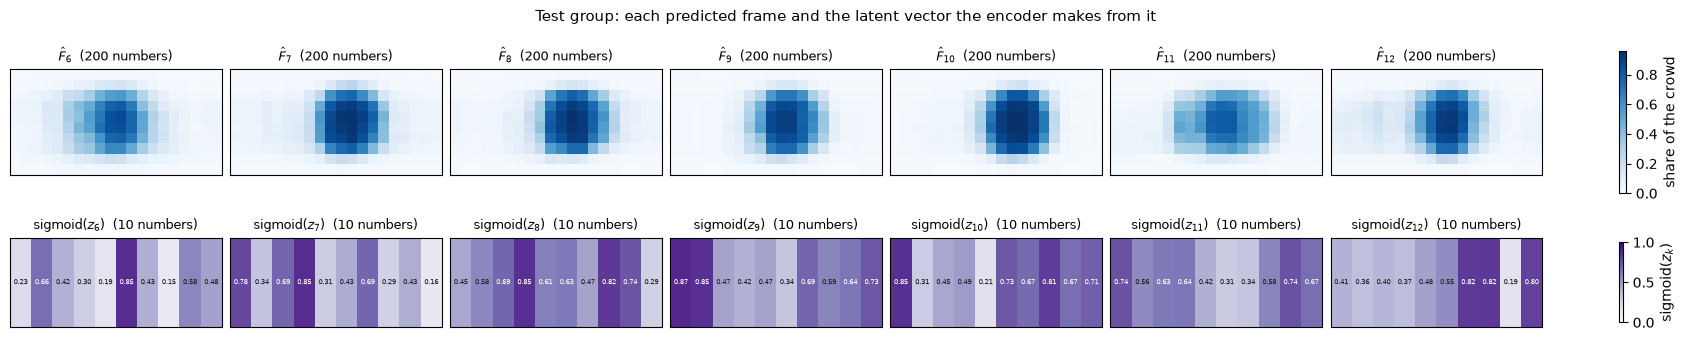

In [14]:
@torch.no_grad()
def encode(F_hat_k, net=enc):
    # F_hat_k: (H, W) or (batch, H, W)  ->  sigmoid(z_k) (batch, L) with z_k drawn from N(mu, sigma^2), plus mu and sigma
    net.eval()
    F = torch.as_tensor(np.asarray(F_hat_k, np.float32), device=DEVICE).reshape(-1, H, W)
    mu, lv = net(F)
    return torch.sigmoid(draw_z(mu, lv)).cpu().numpy(), mu.cpu().numpy(), torch.exp(0.5 * lv).cpu().numpy()


Z_te, MU_z, SIG_z = encode(A_te_v)
print(f"{len(A_te_v)} frames of {H * W} numbers  ->  sigmoid(z_k) of shape {Z_te.shape}  ({H * W // vcfg.L}x smaller)")
print()

rows = [f"k={k} ({5 * k} s)" for k in KS]
cols = [f"[{d + 1}]" for d in range(vcfg.L)]
print("sigmoid(z_k) (one draw per frame):");  print(pd.DataFrame(Z_te,  index=rows, columns=cols).round(2).to_string(), "\n")
print("mu_z:");                      print(pd.DataFrame(MU_z,  index=rows, columns=cols).round(2).to_string(), "\n")
print("sigma_z:");                   print(pd.DataFrame(SIG_z, index=rows, columns=cols).round(2).to_string())

# figure: each test frame above its 10 latent numbers sigmoid(z_k)
fig, axes = plt.subplots(2, len(KS), figsize=(2.4 * len(KS), 3.3), constrained_layout=True,
                         gridspec_kw={"height_ratios": [2, 1]})
for col, k in enumerate(KS):
    im0 = axes[0, col].imshow(A_te_v[col], cmap="Blues", vmin=0, vmax=float(A_te_v.max()), interpolation="nearest")
    axes[0, col].set_title(f"$\\hat F_{{{k}}}$  (200 numbers)", fontsize=9)
    im1 = axes[1, col].imshow(Z_te[col][None, :], cmap="Purples", vmin=0, vmax=1, interpolation="nearest", aspect="auto")
    axes[1, col].set_title(f"sigmoid($z_{{{k}}}$)  (10 numbers)", fontsize=9)
    for d, v in enumerate(Z_te[col]):
        axes[1, col].text(d, 0, f"{v:.2f}", ha="center", va="center", fontsize=5,
                          color="white" if v > 0.6 else "#1d1d1f")
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im0, ax=axes[0], shrink=0.8, label="share of the crowd")
fig.colorbar(im1, ax=axes[1], shrink=0.9, label="sigmoid($z_k$)")
fig.suptitle("Test group: each predicted frame and the latent vector the encoder makes from it", fontsize=11)
fig.savefig(os.path.join(FIG_DIR, "latent_vectors.png"), dpi=150)
plt.show()
